# 🚀 VLA 연구 · 7회차 실습
## Transformer · ViT 원리 & SayCan·Hi Robot 논문 4단계 리뷰

| 항목 | 내용 |
|------|------|
| 오늘 목표 | Transformer Self-Attention 구현, ViT 이미지 패치화, Hugging Face 기초, 논문 4단계 리뷰 |
| 미니과제 | 우리 연구 한 문단 설명 챌린지 |
| 제출 방법 | 완성된 노트북을 공용 드라이브 공유 폴더에 저장 후 조교에게 링크 공유 |

> **이 노트북을 여는 순서**  
> 런타임 → 런타임 유형 변경 → **GPU (T4)** 선택 후 저장


>시각화 시 사용할 한글 폰트 설정 (아래 블록 실행 후 **런타임 재시작**)

In [ ]:
# 한글 폰트 설정 (Colab 환경)
import matplotlib
import matplotlib.font_manager as fm

## Colab에 나눔폰트 설치
import subprocess
subprocess.run(['apt-get', 'install', '-y', 'fonts-nanum'], capture_output=True)
fm._load_fontmanager(try_read_cache=False)  # 폰트 캐시 갱신

## 나눔고딕 적용
matplotlib.rcParams['font.family'] = 'NanumGothic'
matplotlib.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지


---
## SECTION 0  |  환경 확인

### 0-1. GPU 및 PyTorch 환경 확인

아래 셀을 실행하여 GPU와 PyTorch 버전을 확인하세요.  
**'No GPU'가 뜨면 런타임 → 런타임 유형 변경 → GPU로 설정하세요.**

In [ ]:
import torch
import sys

print('=== 환경 정보 ===')
print(f'Python  : {sys.version.split()[0]}')
print(f'PyTorch : {torch.__version__}')

if torch.cuda.is_available():
    print(f'GPU     : {torch.cuda.get_device_name(0)}')
    print(f'CUDA    : {torch.version.cuda}')
    device = torch.device('cuda')
    print('\n✓ GPU 사용 준비 완료')
else:
    print('⚠ GPU 없음 — 런타임 유형을 GPU로 변경하세요')
    device = torch.device('cpu')

print(f'\n사용 디바이스: {device}')


---
## SECTION 1  |  Google Drive 마운트 & 공용 드라이브 연결

### 1-1. 개인 Drive 마운트

개인 Drive를 마운트합니다. 노트북 작업 파일의 임시 저장·백업용으로 활용합니다.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_BASE = '/content/drive/MyDrive/VLA_2026'
os.makedirs(DRIVE_BASE, exist_ok=True)
print(f'Drive 마운트 완료: {DRIVE_BASE}')


### 1-2. 공유 폴더 마운트

팀 공유 파일은 공유 폴더를 사용하여 관리합니다.  
**처음 실행 시**:

* 제공된 공유 폴더 링크에 접속합니다. (https://drive.google.com/drive/folders/1sP0yHhKYPg2tGAe3GXdMIGWjvWoj3FyV)

* 상단의 폴더 이름 옆 화살표를 누르거나 폴더를 우클릭하여 '드라이브에 바로가기 추가'를 클릭합니다.

* '내 드라이브'를 선택하고 바로가기를 생성합니다.

> **5회차와 동일**: 구글 드라이브 공유 폴더를 그대로 사용합니다.


In [ ]:
# 1. 공유 폴더 설정
# '내 드라이브'에 추가한 바로가기 폴더의 이름을 입력하세요.
FOLDER_NAME = 'VLA_Team_2026'
SHARED_DRIVE_PATH = f'/content/drive/MyDrive/{FOLDER_NAME}'

# 2. 팀 공유 폴더 구조 정의
TEAM_PATHS = {
    'notebooks'    : f'{SHARED_DRIVE_PATH}/notebooks/',
    'results'      : f'{SHARED_DRIVE_PATH}/results/',
    'models'       : f'{SHARED_DRIVE_PATH}/models/',
    'data'         : f'{SHARED_DRIVE_PATH}/data/',
}

# 3. 경로 유효성 확인
print(f"설정된 경로: {SHARED_DRIVE_PATH}\n")

if os.path.exists(SHARED_DRIVE_PATH):
    for name, path in TEAM_PATHS.items():
        if os.path.exists(path):
            print(f'✓ {name:12s}: 연결 완료')
        else:
            print(f'⚠ {name:12s}: 폴더 미생성 — {path}')
else:
    print(f'❌ 오류: "{FOLDER_NAME}" 폴더를 찾을 수 없습니다.')
    print('   -> 구글 드라이브에서 "드라이브에 바로가기 추가"를 완료했는지 확인하세요.')


### 1-3. 파일 저장 편의 함수

매번 경로를 타이핑하는 대신 Python 함수로 편하게 사용합니다.  
이후 회차에서도 이 함수들을 재사용합니다.

In [ ]:
import shutil
import os
from datetime import datetime

def team_save(local_path: str, folder: str = 'notebooks'):
    """로컬 파일을 공유 폴더 내 지정된 디렉토리로 복사"""
    if 'TEAM_PATHS' not in globals():
        print("❌ 오류: TEAM_PATHS가 정의되지 않았습니다. 마운트 블록을 먼저 실행하십시오.")
        return None

    target_dir = TEAM_PATHS.get(folder)
    if not target_dir:
        print(f"❌ 오류: 유효하지 않은 폴더 키입니다. (선택 가능: {list(TEAM_PATHS.keys())})")
        return None

    os.makedirs(target_dir, exist_ok=True)
    filename = os.path.basename(local_path)
    target_path = os.path.join(target_dir, filename)

    try:
        shutil.copy2(local_path, target_path)
        print(f'✓ 공유 폴더 저장 완료: {target_path}')
        return target_path
    except PermissionError:
        print(f'❌ 권한 오류: 해당 공유 폴더에 쓰기 권한이 있는지 확인하십시오.')
    except Exception as e:
        print(f'❌ 저장 실패: {e}')
    return None

def team_load(filename: str, folder: str = 'data'):
    """공유 폴더 내 파일을 코랩 가상 머신의 /tmp 디렉토리로 복사 후 경로 반환"""
    if 'TEAM_PATHS' not in globals():
        print("❌ 오류: TEAM_PATHS가 정의되지 않았습니다.")
        return None

    src = os.path.join(TEAM_PATHS.get(folder, ''), filename)
    if not os.path.exists(src):
        print(f"❌ 파일 미발견: {src}\n   파일명과 폴더 위치를 다시 확인하십시오.")
        return None

    dst = os.path.join('/tmp', filename)
    try:
        shutil.copy2(src, dst)
        print(f'✓ 로컬 로드 완료: {dst}')
        return dst
    except Exception as e:
        print(f'❌ 로드 실패: {e}')
        return None

print('✓ 공유 폴더 편의 함수 등록 완료')


---
## SECTION 2  |  Self-Attention — Transformer의 핵심

### 2-1. 왜 Transformer인가?

> **5회차 복습**: CNN은 지역적 패턴(에지, 텍스처)을 잘 잡지만,  
> 이미지의 **멀리 떨어진 부분 간의 관계**를 파악하기 어렵습니다.  
> 예: 'blocked 박스 앞의 장애물을 push해야 한다'는 판단은 박스와 장애물 사이의 공간적 관계가 필요합니다.

Transformer는 **Self-Attention** 메커니즘으로 입력의 모든 위치 쌍을 동시에 비교합니다.  
거리와 무관하게 관련 있는 부분끼리 연결할 수 있어 VLM·VLA의 핵심 기반이 됩니다.

> **VLA 파이프라인 연결**: 우리 연구의 VLM(LLaVA/Qwen2-VL)과 smolVLA 모두  
> Transformer 기반입니다. 오늘 구현하는 Self-Attention이 이 모델들의 핵심 연산입니다.


트랜스포머 강의 :
1. https://www.youtube.com/watch?v=g38aoGttLhI&t=39s
2. https://www.youtube.com/watch?v=_Z3rXeJahMs
3. https://www.youtube.com/watch?v=zHQLPJ8-9Qc


### 2-2. Scaled Dot-Product Attention

Self-Attention의 연산 과정:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

| 행렬 | 의미 | 비유 |
|------|------|------|
| **Q** (Query) | 현재 토큰이 묻는 것 | "나는 어떤 정보가 필요한가?" |
| **K** (Key) | 각 토큰이 광고하는 것 | "나는 이런 정보를 가지고 있다" |
| **V** (Value) | 실제로 전달할 내용 | 정보의 실제 값 |

$\sqrt{d_k}$로  나누는 이유: dot product 값이 너무 커지면 softmax :기울기가 0에 가까워집니다.

$d_k$ :  Key 벡터의 차원 수(Dimension of Keys)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Args:
        Q: (batch, heads, seq_len, d_k)
        K: (batch, heads, seq_len, d_k)
        V: (batch, heads, seq_len, d_v)
    Returns:
        output: (batch, heads, seq_len, d_v)
        attn_weights: (batch, heads, seq_len, seq_len)
    """
    d_k = Q.size(-1)

    # 1. Q와 K의 내적 → 유사도 행렬
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)  # (batch, heads, seq, seq)

    # 2. mask 적용 (padding 위치 무시)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float('-inf'))

    # 3. Softmax → 확률 분포 (attention weights)
    attn_weights = F.softmax(scores, dim=-1)  # 각 행의 합 = 1

    # 4. V에 가중합 적용
    output = torch.matmul(attn_weights, V)

    return output, attn_weights

# 테스트: 4개 토큰, d_k=8
batch, heads, seq_len, d_k = 1, 1, 4, 8
Q = torch.randn(batch, heads, seq_len, d_k)
K = torch.randn(batch, heads, seq_len, d_k)
V = torch.randn(batch, heads, seq_len, d_k)

output, attn = scaled_dot_product_attention(Q, K, V)
print(f'Q shape: {Q.shape}')
print(f'Attention weights shape: {attn.shape}  # (batch, heads, seq_len, seq_len)')
print(f'Output shape: {output.shape}')
print(f'\nAttention weights (합 = 1 확인):\n{attn[0, 0].round(decimals=3)}')
print(f'각 행의 합: {attn[0, 0].sum(dim=-1)}')


### 2-3. Attention 시각화

Attention weights가 어디에 집중하는지 시각화합니다.  
실제 언어 모델에서 'it'이라는 단어가 앞의 어떤 명사를 가리키는지 파악하는 것과 같은 원리입니다.

In [ ]:
import matplotlib.pyplot as plt
import torch

# 간단한 예: 7개 토큰 문장에서의 attention
tokens = ['[CLS]', 'box', 'is', 'blocked', 'push', 'it', '[SEP]']
seq_len = len(tokens)

# 인위적으로 만든 attention: 'blocked'가 'push'에 강하게 주목
torch.manual_seed(7)
attn_demo = torch.softmax(torch.randn(seq_len, seq_len) * 0.5, dim=-1) # 노이즈 감소

# 'blocked'(idx=3) → 'push'(idx=4) 강조 : 문맥 부여
attn_demo[3, 4] += 3.0
attn_demo[3] = torch.softmax(attn_demo[3], dim=0)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(attn_demo.numpy(), cmap='Blues', vmin=0)
ax.set_xticks(range(seq_len))
ax.set_yticks(range(seq_len))
ax.set_xticklabels(tokens, fontsize=11)
ax.set_yticklabels(tokens, fontsize=11)
ax.set_xlabel('Key (어디에서 가져오는가)')
ax.set_ylabel('Query (어느 토큰이 묻는가)')
ax.set_title('Self-Attention 시각화\n(진할수록 강한 attention)', fontsize=12)
for i in range(seq_len):
    for j in range(seq_len):
        ax.text(j, i, f'{attn_demo[i,j]:.2f}', ha='center', va='center',
                fontsize=8, color='white' if attn_demo[i,j] > 0.3 else 'black')
plt.colorbar(im)
plt.tight_layout()
plt.show()


---
## SECTION 3  |  Multi-Head Attention & Transformer 블록

### 3-1. Multi-Head Attention (MHA)

단일 attention head는 하나의 관점에서만 관계를 파악합니다.  
**MHA**는 여러 head를 병렬로 사용하여 **다양한 관점**의 관계를 동시에 학습합니다.

```
MHA 과정:
1. Q, K, V를 h개의 head로 선형 투영 (d_model → d_k × h)
2. 각 head에서 독립적으로 Attention 수행
3. h개 head의 출력을 concat → 선형 투영으로 원래 차원으로 복원
```

> **왜 여러 head가 필요한가?**  
> Head 1: 문법적 관계 포착 / Head 2: 의미적 유사성 / Head 3: 위치 관계 ...  
> 실제 VLM에서 일부 head는 이미지의 물체 경계를, 다른 head는 텍스트 의미를 담당합니다.

In [ ]:
import torch
import torch.nn as nn

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int):
        super().__init__()
        assert d_model % num_heads == 0, 'd_model은 num_heads로 나누어져야 합니다'
        self.d_model    = d_model
        self.num_heads  = num_heads
        self.d_k        = d_model // num_heads

        # Q, K, V 선형 투영
        self.W_Q = nn.Linear(d_model, d_model)
        self.W_K = nn.Linear(d_model, d_model)
        self.W_V = nn.Linear(d_model, d_model)
        self.W_O = nn.Linear(d_model, d_model)  # 출력 투영

    def split_heads(self, x):
        """(batch, seq, d_model) → (batch, heads, seq, d_k)"""
        batch, seq, _ = x.shape
        return x.view(batch, seq, self.num_heads, self.d_k).transpose(1, 2)

    def forward(self, x):
        batch, seq, _ = x.shape

        # 선형 투영 후 head 분리
        Q = self.split_heads(self.W_Q(x))  # (batch, heads, seq, d_k)
        K = self.split_heads(self.W_K(x))
        V = self.split_heads(self.W_V(x))

        # Scaled Dot-Product Attention
        import math
        import torch.nn.functional as F
        scores  = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        weights = F.softmax(scores, dim=-1)
        attn_out = torch.matmul(weights, V)  # (batch, heads, seq, d_k)

        # head 합치기: (batch, heads, seq, d_k) → (batch, seq, d_model)
        attn_out = attn_out.transpose(1, 2).contiguous().view(batch, seq, self.d_model)

        return self.W_O(attn_out), weights

# 테스트
d_model, num_heads, seq_len = 64, 8, 10
mha = MultiHeadAttention(d_model, num_heads)
x = torch.randn(2, seq_len, d_model)  # (batch=2, seq=10, d_model=64)
out, attn_w = mha(x)
print(f'입력  shape: {x.shape}')
print(f'출력  shape: {out.shape}')
print(f'Attention weights: {attn_w.shape}  # (batch, heads, seq, seq)')


In [ ]:
import matplotlib.pyplot as plt

def visualize_mha(tokens, attn_weights, batch_idx=0):
    """
    attn_weights: (batch, num_heads, seq_len, seq_len) 형태의 텐서
    """
    num_heads = attn_weights.shape[1]
    cols = 4
    rows = num_heads // cols

    fig, axes = plt.subplots(rows, cols, figsize=(16, 8))
    axes = axes.flatten()

    for i in range(num_heads):
        ax = axes[i]
        # 특정 헤드의 가중치 추출
        head_attn = attn_weights[batch_idx, i].detach().numpy()

        im = ax.imshow(head_attn, cmap='Blues')
        ax.set_title(f'Head {i+1}')

        # 첫 번째 열과 마지막 행에만 토큰 표시 (가독성 제고)
        if i % cols == 0:
            ax.set_yticks(range(len(tokens)))
            ax.set_yticklabels(tokens, fontsize=9)
        else:
            ax.set_yticks([])

        if i >= (rows - 1) * cols:
            ax.set_xticks(range(len(tokens)))
            ax.set_xticklabels(tokens, fontsize=9, rotation=45)
        else:
            ax.set_xticks([])

    plt.suptitle('Multi-Head Attention Visualization', fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# 사용 예시
tokens = "The animal didn't cross the street because it was too tired".split()
# 실제 학습된 모델이 아니므로 여기서는 attn_w 결과를 그대로 전달
visualize_mha(tokens, attn_w)

### 3-2. Positional Encoding

Transformer는 순서를 모릅니다 — Attention은 병렬 처리라 위치 정보가 없습니다.  
**Positional Encoding**은 각 위치에 고유한 신호를 더해 순서 정보를 주입합니다.

원래 Transformer(Vaswani et al., 2017)는 sin/cos 함수를 사용합니다:
$$PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$
$$PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

In [ ]:
import torch
import math
import matplotlib.pyplot as plt

def positional_encoding(max_seq_len: int, d_model: int):
    """sin/cos 기반 Positional Encoding 행렬 생성"""
    PE = torch.zeros(max_seq_len, d_model)
    pos = torch.arange(0, max_seq_len, dtype=torch.float).unsqueeze(1)  # (seq, 1)
    div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))

    PE[:, 0::2] = torch.sin(pos * div)  # 짝수 차원: sin
    PE[:, 1::2] = torch.cos(pos * div)  # 홀수 차원: cos
    return PE

pe = positional_encoding(max_seq_len=50, d_model=64)
print(f'PE shape: {pe.shape}  # (max_seq_len, d_model)')

# 시각화
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# 왼쪽: PE 행렬 전체
axes[0].imshow(pe.numpy(), cmap='RdBu', aspect='auto', vmin=-1, vmax=1)
axes[0].set_title('Positional Encoding 행렬 (50 positions × 64 dims)')
axes[0].set_xlabel('차원 (d_model)')
axes[0].set_ylabel('위치 (position)')
plt.colorbar(axes[0].images[0], ax=axes[0])

# 오른쪽: 처음 4개 차원의 PE 값
for dim in range(4):
    axes[1].plot(pe[:, dim].numpy(), label=f'dim {dim}')
axes[1].set_title('처음 4개 차원의 PE 곡선')
axes[1].set_xlabel('위치')
axes[1].set_ylabel('PE 값')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


현재 대규모 언어 모델(LLM) 분야에서 가장 널리 사용되는 포지셔널 인코딩 방식은 **RoPE(Rotary Positional Embedding)**


* 회전 행렬의 적용: 위치 $m$에 있는 토큰의 벡터에 대해, 위치값에 비례하는 회전 행렬을 곱한다
$$ \begin{pmatrix} q_m^{(1)} \\ q_m^{(2)} \end{pmatrix} \to \begin{pmatrix} \cos m\theta & -\sin m\theta \\ \sin m\theta & \cos m\theta \end{pmatrix} \begin{pmatrix} q_m^{(1)} \\ q_m^{(2)} \end{pmatrix} $$

* 상대적 거리의 보존: 두 토큰 사이의 어텐션 점수를 계산하기 위해 Q와 K를 내적하면, 절대 위치 정보는 상쇄되고 두 위치의 차이($m-n$)에 해당하는 상대적 거리 정보만 남게 된다

단순히 위치 정보를 더하는 경우 모델은 의미 정보(Semantic)와 위치 정보(Position)가 섞인 덩어리에서 두 정보를 분리하여 해석해야 한다 (기존의 방식)

반면, RoPE는 벡터를 회전(Rotation)시키는 곱셈 방식을 취함으로써 위치 정보가 별도의 벡터로 존재하는 것이 아니라, 쿼리(Q)와 키(K) 벡터의 회전 각도 자체에 내재되게 만든다 - 토큰 간의 '상대적 관계'를 어텐션 메커니즘 안에 직접적으로 녹여낸다.

In [ ]:
import torch
import matplotlib.pyplot as plt

def get_rope_embeddings(max_seq_len: int, d_model: int):
    """RoPE의 핵심이 되는 sin, cos 회전 성분 생성"""
    # θ 계산: 차원 쌍마다 주기가 달라짐 (d_model/2 개의 theta 생성)
    theta = 1.0 / (10000 ** (torch.arange(0, d_model, 2).float() / d_model))

    m = torch.arange(max_seq_len).float()
    angles = m[:, None] * theta[None, :]  # (seq_len, d_model/2)

    cos = torch.cos(angles)
    sin = torch.sin(angles)
    return cos, sin

def apply_rope(x, cos, sin):
    """RoPE 적용: 각 차원 쌍마다 해당 각도로 회전"""
    # x: (seq_len, d_model)
    x1 = x[:, 0::2]  # 짝수 차원
    x2 = x[:, 1::2]  # 홀수 차원

    # ✅ 수정: cos[:, 0]이 아닌 cos 전체를 사용해 각 차원 쌍에 맞는 각도 적용
    x_rotated = torch.stack([
        x1 * cos - x2 * sin,
        x1 * sin + x2 * cos
    ], dim=-1)

    # (seq_len, d_model/2, 2) → (seq_len, d_model)
    return x_rotated.flatten(-2)

max_seq = 20

# ── 왼쪽 heatmap: 다양한 주기를 보여주려면 충분한 차원 필요 ──
d_heatmap = 64  # ✅ 수정: 2 → 64 (차원 쌍이 32개 → 주기 다양성 시각화 가능)
cos_hm, _ = get_rope_embeddings(max_seq, d_heatmap)

# ── 오른쪽 회전 시각화: 2차원 벡터 회전이므로 d_model=2 유지 ──
d_vis = 2
cos_v, sin_v = get_rope_embeddings(max_seq, d_vis)

initial_vector = torch.tensor([1.0, 0.0]).repeat(max_seq, 1)
rotated_vectors = apply_rope(initial_vector, cos_v, sin_v)

# ── 시각화 ──
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 왼쪽: heatmap (d_model=64으로 다양한 주기 확인)
im = axes[0].imshow(cos_hm.numpy(), cmap='RdBu', aspect='auto')
axes[0].set_title('RoPE 회전 성분 (cos mθ)\n차원 쌍마다 주기가 다름을 확인')
axes[0].set_xlabel('차원 쌍 (Dimension Pair)')
axes[0].set_ylabel('위치 (Position)')
plt.colorbar(im, ax=axes[0])

# 오른쪽: 2D 회전 시각화
v_np = rotated_vectors.detach().numpy()
for i in range(max_seq):
    axes[1].quiver(0, 0, v_np[i, 0], v_np[i, 1],
                   angles='xy', scale_units='xy', scale=1,
                   color=plt.cm.viridis(i / max_seq), alpha=0.8,
                   label=f'pos {i}' if i % 5 == 0 else "")

axes[1].set_xlim(-1.2, 1.2)
axes[1].set_ylim(-1.2, 1.2)
axes[1].axhline(0, color='black', lw=1)
axes[1].axvline(0, color='black', lw=1)
axes[1].set_title('위치(m)에 따른 벡터의 회전\n(첫 번째 차원 쌍, θ₀=1.0)')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 3-3. Transformer 인코더 블록

실제 Transformer는 아래 구조를 N번 쌓습니다:

```
Input
  ↓ + Positional Encoding
  ↓ Multi-Head Attention
  ↓ + Residual Connection → LayerNorm  ← Add & Norm
  ↓ Feed-Forward Network (2-layer MLP)
  ↓ + Residual Connection → LayerNorm  ← Add & Norm
Output
```

**Residual Connection**: 입력을 그대로 더해 기울기 소실 방지 (ResNet과 같은 원리)

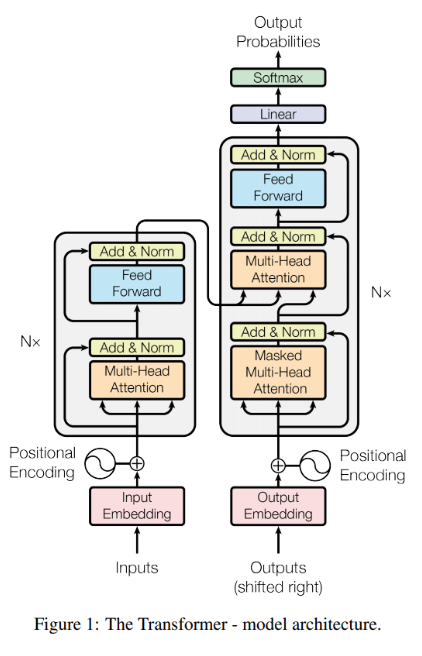

In [ ]:
import torch
import torch.nn as nn

class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model: int, num_heads: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.attn    = MultiHeadAttention(d_model, num_heads)
        self.norm1   = nn.LayerNorm(d_model)
        self.norm2   = nn.LayerNorm(d_model)
        self.ff      = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),              # 최신 Transformer는 GELU 사용
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # 1. Multi-Head Attention + Residual + LayerNorm
        attn_out, _ = self.attn(x)
        x = self.norm1(x + self.dropout(attn_out))

        # 2. Feed-Forward + Residual + LayerNorm
        ff_out = self.ff(x)
        x = self.norm2(x + self.dropout(ff_out))
        return x

# 테스트
block = TransformerEncoderBlock(d_model=64, num_heads=8, d_ff=256)
x = torch.randn(2, 10, 64)  # (batch=2, seq=10, d_model=64)
out = block(x)
print(f'입력 shape : {x.shape}')
print(f'출력 shape : {out.shape}  # 동일 유지 (residual connection)')
total = sum(p.numel() for p in block.parameters())
print(f'블록 파라미터 수: {total:,}')


### 3-4. 연습문제 ✏️

아래 문제를 풀어보세요.
* 우선 스스로 작성해 보세요.
* 막힌다면 충분히 고민한 이후에 Claude Code에 질문하세요.

In [ ]:
# 문제 1
# d_model=128, num_heads=4 인 MultiHeadAttention을 만들고
# (batch=3, seq=20, d_model=128) 입력에 대해 출력 shape을 확인하세요.
# 또한 이 MHA의 파라미터 수(W_Q, W_K, W_V, W_O)를 손으로 계산하고 코드로 검증하세요.

# 여기에 코드 작성


In [ ]:
# 문제 2
# positional_encoding(max_seq_len=100, d_model=32)를 생성하고
# 위치 0, 25, 50, 75의 PE 벡터 사이의 코사인 유사도를 계산하세요.
# 위치가 가까울수록 유사도가 높은지 확인하세요.
# 힌트: F.cosine_similarity(pe[i].unsqueeze(0), pe[j].unsqueeze(0))

# 여기에 코드 작성



In [ ]:
# 문제 3
# TransformerEncoderBlock을 2개 쌓은 Mini Transformer를 만들고
# (batch=2, seq=8, d_model=32) 입력을 통과시켜 출력 shape을 확인하세요.
# 힌트: nn.Sequential 또는 for 루프로 블록을 쌓을 수 있습니다.

# 여기에 코드 작성



---
## SECTION 4  |  Vision Transformer (ViT) — 이미지 패치 분할

### 4-1. ViT 아이디어: 이미지를 '토큰' 서열로

> **핵심 아이디어**: 이미지를 작은 패치로 잘라서 **순서가 있는 토큰**으로 만들면  
> 그대로 Transformer에 넣을 수 있습니다.

ViT 처리 과정:
```
이미지 (3, 224, 224)
  ↓ 패치 분할: 16×16 패치로 자르면 → 14×14 = 196개 패치
  ↓ 각 패치를 1D로 펼침: 16×16×3 = 768 차원
  ↓ 선형 투영: 768 → d_model
  ↓ + [CLS] 토큰 prepend + Positional Encoding
  ↓ Transformer Encoder (N 블록)
  ↓ [CLS] 토큰 출력 → 분류 헤드
```

> **VLA 파이프라인 연결**: smolVLA의 이미지 인코더가 정확히 이 구조를 씁니다.  
> MuJoCo 씬 이미지(3, H, W)가 패치로 분할되어 Transformer에 입력됩니다.

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

def patchify(img: torch.Tensor, patch_size: int):
    """
    이미지를 패치로 분할합니다.
    Args:
        img: (batch, C, H, W)
        patch_size: 패치 크기 (예: 16)
    Returns:
        patches: (batch, num_patches, patch_size^2 * C)
    """
    batch, C, H, W = img.shape
    assert H % patch_size == 0 and W % patch_size == 0

    num_patches_h = H // patch_size
    num_patches_w = W // patch_size
    num_patches   = num_patches_h * num_patches_w

    # (B, C, H, W) → (B, num_patches, patch_size^2 * C)
    patches = img.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)
    # patches: (B, C, num_h, num_w, patch_size, patch_size)
    patches = patches.contiguous().view(batch, C, num_patches_h, num_patches_w,
                                         patch_size * patch_size)
    patches = patches.permute(0, 2, 3, 1, 4).contiguous()
    patches = patches.view(batch, num_patches, C * patch_size * patch_size)
    return patches

# 테스트: 32×32 이미지, 8×8 패치
img = torch.randn(1, 3, 32, 32)
patch_size = 8
patches = patchify(img, patch_size)

print(f'원본 이미지  : {img.shape}')
print(f'패치 수      : {(32//8)**2}  (= {32//8} × {32//8})')
print(f'패치 텐서    : {patches.shape}  # (batch, num_patches, patch_dim)')
print(f'패치 차원    : {3 * patch_size**2}  (= C × pH × pW)')


### 4-2. 패치 분할 시각화

In [ ]:
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import torch
import numpy as np

# 1. Patchify 함수 정의 (B, C, H, W -> B, N, C, P, P)
def patchify(images, patch_size):
    n, c, h, w = images.shape
    p = patch_size
    # 이미지를 패치 크기로 분할
    # (B, C, H, W) -> (B, C, H/P, P, W/P, P)
    x = images.reshape(n, c, h // p, p, w // p, p)
    # 차원 재배치: (B, H/P, W/P, C, P, P)
    x = x.permute(0, 2, 4, 1, 3, 5)
    # 패치 개수로 평탄화: (B, N, C, P, P)
    x = x.reshape(n, (h // p) * (w // p), c, p, p)
    return x

# MNIST 샘플 이미지 준비
transform = transforms.Compose([transforms.Resize(32), transforms.ToTensor()])
sample_ds = datasets.MNIST(root='/tmp/mnist', train=True, download=True, transform=transform)
sample_img = sample_ds[0][0].unsqueeze(0)  # (1, 1, 32, 32)

# 패치 분할 (패치 하나 크기 : 8x8 크기)
patch_size = 8
patches = patchify(sample_img, patch_size=patch_size) # (1, 16, 1, 8, 8)

# 시각화 설정 (5행 4열)
fig, axes = plt.subplots(5, 4, figsize=(10, 12))
axes_flat = axes.flatten()

# 1. 원본 이미지 표시 (첫 번째 칸)
axes_flat[0].imshow(sample_img[0, 0].numpy(), cmap='gray')
axes_flat[0].set_title('Original (32×32)', fontsize=10)
axes_flat[0].axis('off')

# 2. 패치 격자 표시 (두 번째 칸)
axes_flat[1].imshow(sample_img[0, 0].numpy(), cmap='gray')
for i in range(0, 33, patch_size):
    axes_flat[1].axhline(i - 0.5, color='red', linewidth=1)
    axes_flat[1].axvline(i - 0.5, color='red', linewidth=1)
axes_flat[1].set_title(f'{patch_size}x{patch_size} Grid', fontsize=10)
axes_flat[1].axis('off')

# 나머지 상단 칸 비우기
for i in range(2, 4):
    axes_flat[i].axis('off')

# 3. 16개 패치 순차적으로 표시 (두 번째 줄부터)
for idx in range(16):
    ax = axes_flat[idx + 4] # 4번째 인덱스부터 패치 출력
    patch = patches[0, idx, 0].numpy()  # (8, 8)
    ax.imshow(patch, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Patch {idx+1}', fontsize=9)
    ax.axis('off')

plt.suptitle(f'ViT Patch Partitioning: 32×32 Image → 16 Patches (8×8)', fontsize=14)
plt.tight_layout()
plt.show()

### 4-3. 간단한 ViT 분류기 구현

완전한 ViT를 처음부터 구현합니다.  
MNIST 32×32 이미지로 테스트합니다.

In [ ]:
import torch
import torch.nn as nn

def patchify(images, patch_size):
    n, c, h, w = images.shape
    p = patch_size
    # (B, C, H, W) -> (B, C, H/P, P, W/P, P)
    x = images.reshape(n, c, h // p, p, w // p, p)
    # 차원 재배치: (B, H/P, W/P, C, P, P)
    x = x.permute(0, 2, 4, 1, 3, 5)
    # 모델 입력을 위해 (B, N, Patch_Dim)으로 변환
    # 여기서 Patch_Dim = C * P * P
    x = x.reshape(n, (h // p) * (w // p), -1)
    return x

# 참고용: 간단한 Transformer Block 정의 (오류 방지용)
class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attn_out, _ = self.attn(x, x, x)
        x = self.norm1(x + attn_out)
        mlp_out = self.mlp(x)
        x = self.norm2(x + mlp_out)
        return x

class SimpleViT(nn.Module):
    def __init__(self, img_size=32, patch_size=8, in_channels=1,
                 num_classes=10, d_model=64, num_heads=4,
                 num_layers=4, d_ff=128, dropout=0.1):
        super().__init__()
        self.patch_size  = patch_size
        self.num_patches = (img_size // patch_size) ** 2
        patch_dim        = in_channels * patch_size * patch_size

        # 1. 패치 선형 투영
        self.patch_embed = nn.Linear(patch_dim, d_model)

        # 2. [CLS] 토큰 (학습 가능한 벡터)
        self.cls_token   = nn.Parameter(torch.randn(1, 1, d_model))

        # 3. Positional Encoding (학습 가능 버전)
        self.pos_embed   = nn.Parameter(torch.randn(1, self.num_patches + 1, d_model))

        # 4. Transformer 인코더
        self.transformer = nn.Sequential(*[
            TransformerEncoderBlock(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])

        # 5. 분류 헤드
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, num_classes)

    def forward(self, x):
        batch = x.size(0)

        # 패치 분할 및 투영
        patches = patchify(x, self.patch_size)     # (B, N, patch_dim)
        tokens  = self.patch_embed(patches)         # (B, N, d_model)

        # [CLS] 토큰 prepend
        cls = self.cls_token.expand(batch, -1, -1)  # (B, 1, d_model)
        tokens = torch.cat([cls, tokens], dim=1)    # (B, N+1, d_model)

        # Positional Encoding 추가
        tokens = tokens + self.pos_embed

        # Transformer 통과
        tokens = self.transformer(tokens)

        # [CLS] 토큰으로 분류
        cls_out = self.norm(tokens[:, 0])  # (B, d_model)
        return self.head(cls_out)           # (B, num_classes)

# 모델 확인
vit = SimpleViT()
x = torch.randn(2, 1, 32, 32)
out = vit(x)
total = sum(p.numel() for p in vit.parameters())
print(f'입력  shape: {x.shape}')
print(f'출력  shape: {out.shape}  # (batch, num_classes)')
print(f'총 파라미터: {total:,}')


### 4-4. ViT vs CNN 비교 학습 (MNIST)

> 이 셀은 ViT와 4회차의 MLP를 같은 데이터로 비교합니다.  
> 데이터가 적을 때 CNN보다 ViT가 불리한 이유를 직접 확인합니다.

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import torch.optim as optim
import torch.nn as nn

# MNIST 32×32 (ViT 입력 크기)
transform_vit = transforms.Compose([
    transforms.Resize(32),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

full_train = torchvision.datasets.MNIST(root='/tmp/mnist', train=True,
                                         download=True, transform=transform_vit)
test_ds    = torchvision.datasets.MNIST(root='/tmp/mnist', train=False,
                                         download=True, transform=transform_vit)

train_ds, val_ds = random_split(full_train, [50000, 10000],
                                 generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2)

# 학습 루프 (5회차 동일 패턴)
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out  = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct    += (out.argmax(1) == y).sum().item()
        total      += x.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out  = model(x)
        loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        correct    += (out.argmax(1) == y).sum().item()
        total      += x.size(0)
    return total_loss / total, correct / total

print('✓ 데이터 로더 및 학습 함수 준비 완료')


In [ ]:
import matplotlib.pyplot as plt

NUM_EPOCHS = 5
vit_model = SimpleViT().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(vit_model.parameters(), lr=3e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

history_vit = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}

print('[SimpleViT on MNIST]')
print(f'{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}')
print('-' * 55)

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(vit_model, train_loader, criterion, optimizer, device)
    vl_loss, vl_acc = evaluate(vit_model, val_loader, criterion, device)
    scheduler.step()
    history_vit['train_loss'].append(tr_loss)
    history_vit['train_acc'].append(tr_acc)
    history_vit['val_loss'].append(vl_loss)
    history_vit['val_acc'].append(vl_acc)
    print(f'{epoch:>5} | {tr_loss:>10.4f} | {tr_acc:>8.2%} | {vl_loss:>8.4f} | {vl_acc:>6.2%}')

test_loss, test_acc = evaluate(vit_model, test_loader, criterion, device)
print(f'\nTest Accuracy: {test_acc:.2%}')


In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), # 지역적 특징 추출
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc = nn.Linear(32 * 8 * 8, 10)

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


NUM_EPOCHS = 5
CNN_model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(CNN_model.parameters(), lr=3e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

history_vit = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}

print('[SimpleCNN on MNIST]')
print(f'{'Epoch':>5} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7}')
print('-' * 55)

for epoch in range(1, NUM_EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(CNN_model, train_loader, criterion, optimizer, device)
    vl_loss, vl_acc = evaluate(CNN_model, val_loader, criterion, device)
    scheduler.step()
    history_vit['train_loss'].append(tr_loss)
    history_vit['train_acc'].append(tr_acc)
    history_vit['val_loss'].append(vl_loss)
    history_vit['val_acc'].append(vl_acc)
    print(f'{epoch:>5} | {tr_loss:>10.4f} | {tr_acc:>8.2%} | {vl_loss:>8.4f} | {vl_acc:>6.2%}')

test_loss, test_acc = evaluate(CNN_model, test_loader, criterion, device)
print(f'\nTest Accuracy: {test_acc:.2%}')


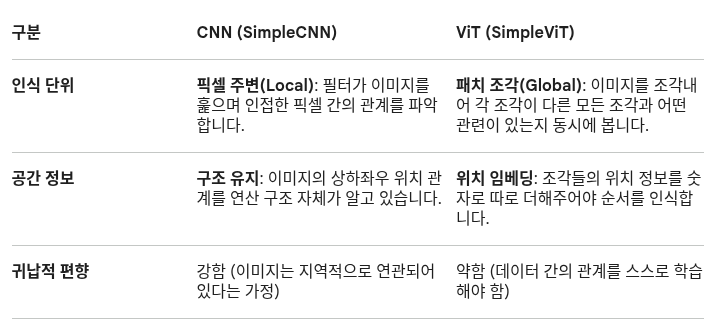

### *"ViT는 언제 사용하나요?"*

1. 데이터의 양이 충분히 많을 때
  
    ViT는 CNN이 가진 '이미지는 지역적으로
    유사하다'는 **귀납적 편향(Inductive Bias)** 이 없습니다. 이는 기초 지식이 없는 상태와 같아서, 스스로 이미지의 특징을 파악하려면 CNN보다 훨씬 더 많은 양의 데이터가 필요합니다.

2. 이미지 전체의 맥락(Global Context) 파악이 중요할 때
  
    CNN은 필터 크기만큼의 좁은 영역만 먼저 보지만, ViT는 시작부터 모든 패치 간의 관계를 계산합니다. 따라서 이미지 내에서 서로 멀리 떨어진 요소들 사이의 관계를 파악해야 하는 작업에 유리합니다.

3. 모델의 크기를 아주 크게 키우고 싶을 때 (Scalability)
  
    ViT는 트랜스포머 구조를 그대로 따르기 때문에, 모델의 크기를 키웠을 때 성능이 비례해서 향상되는 '확장성'이 매우 뛰어납니다. 대규모 컴퓨팅 자원을 투입할 수 있는 환경에서 유리합니다.

4. **텍스트와 이미지를 함께 다룰 때 (Multi-modal)**
  
    현재 자연어 처리(NLP)의 표준은 트랜스포머입니다. 이미지 또한 트랜스포머 구조인 ViT를 사용하면, 텍스트 정보와 이미지 정보를 같은 형식으로 처리할 수 있어 두 데이터를 합치기가 매우 수월해집니다.

---
## SECTION 5  |  임베딩 · Hugging Face · VLM — 텍스트와 이미지를 하나의 공간으로

### 5-0. 임베딩(Embedding)이란?

컴퓨터는 텍스트나 이미지를 그대로 처리할 수 없습니다.  
**임베딩**은 의미를 보존하면서 데이터를 **고차원 벡터**로 변환하는 것입니다.

| 변환 전 | 변환 후 |
|---------|--------|
| `'pick'` (문자열) | `[0.21, -0.84, 0.13, ...]` (384차원 실수 벡터) |
| 32×32 이미지 | `[0.05, 0.91, -0.33, ...]` (384차원 실수 벡터) |

**핵심 성질**: 의미가 비슷한 것끼리 벡터 공간에서 **가까이** 위치합니다.

```
벡터 공간 (개념도)

  pick ●──────● accessible    ← 둘 다 '접근 가능' 맥락 → 가까움
  push ●                      ← 물리적 행동 → pick과 어느 정도 가까움
                ● ignore      ← 다른 맥락 → 멀리 위치
```

> **VLA 파이프라인 연결**:  
> - 텍스트 임베딩: VLM이 "A 구역의 택배를 정리하시오"를 이해할 때  
> - 이미지 임베딩: VLM이 씬 이미지를 분석할 때  
> - **두 임베딩을 같은 공간에 놓고 비교**하는 것이 오늘 VLM 실습의 핵심입니다.

* 토큰 & 임베딩 참고 코드 :
https://colab.research.google.com/github/HandsOnLLM/Hands-On-Large-Language-Models/blob/main/chapter02/Chapter%202%20-%20Tokens%20and%20Token%20Embeddings.ipynb

In [ ]:
# ── 임베딩 개념 시각화: 간단한 단어 임베딩 예시 ─────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# 설명용 2D 임베딩 (실제 모델 벡터를 2D로 투영한 것을 흉내낸 예시)
# 실제 임베딩은 수백 차원이지만, 핵심 관계는 이렇게 나타납니다
words = [
    # (단어, x, y, 색상, 그룹)
    ('pick',           0.8,  0.7, 'royalblue',     'action'),
    ('push',           0.3,  0.5, 'royalblue',     'action'),
    ('reorder',        0.1,  0.8, 'royalblue',     'action'),
    ('ignore',        -0.2,  0.9, 'royalblue',     'action'),
    ('accessible',     0.9,  0.4, 'mediumseagreen','state'),
    ('blocked',       -0.1,  0.3, 'mediumseagreen','state'),
    ('box',            0.5, -0.1, 'tomato',        'object'),
    ('parcel',         0.6, -0.3, 'tomato',        'object'),
    ('obstacle',      -0.2,  0.0, 'tomato',        'object'),
    ('zone A',        -0.6, -0.5, 'darkorange',    'location'),
    ('zone B',        -0.8, -0.3, 'darkorange',    'location'),
    ('warehouse',     -0.5, -0.7, 'darkorange',    'location'),
]

color_map = {
    'action':   'royalblue',
    'state':    'mediumseagreen',
    'object':   'tomato',
    'location': 'darkorange',
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── 왼쪽: 임베딩 공간 산점도 ────────────────────────────────
ax = axes[0]
for word, x, y, color, group in words:
    ax.scatter(x, y, s=200, color=color, zorder=3, edgecolors='white', linewidth=1.5)
    ax.annotate(word, (x, y), textcoords='offset points', xytext=(8, 4),
                fontsize=10, fontweight='bold', color=color)

# 같은 그룹끼리 점선 원으로 묶기
from matplotlib.patches import Ellipse
group_bounds = [
    # (라벨, [중심_x, 중심_y], [가로_반경, 세로_반경], 색상)
    ('Actions\n(행동)',   [0.3,  0.7],  [0.6, 0.3],  'royalblue'),
    ('States\n(상태)',    [0.4,  0.35], [0.6, 0.15], 'mediumseagreen'),
    ('Objects\n(물체)',   [0.2, -0.15], [0.5, 0.25], 'tomato'),
    ('Locations\n(위치)', [-0.65, -0.5], [0.25, 0.3], 'darkorange'),
]
for label, center, radii, color in group_bounds:
    # radii[0]*2, radii[1]*2를 통해 전체 너비와 높이 설정
    e = Ellipse(center, radii[0]*2, radii[1]*2,
                color=color, fill=True, alpha=0.08, linestyle='--', linewidth=1.5)
    ax.add_patch(e)
    ax.text(center[0], center[1] - radii[1] - 0.08, label,
            ha='center', va='center', fontsize=8.5, color=color,
            fontweight='bold')

ax.set_xlim(-1.1, 1.3)
ax.set_ylim(-1.0, 1.1)
ax.axhline(0, color='lightgray', linewidth=0.8)
ax.axvline(0, color='lightgray', linewidth=0.8)
ax.set_title('임베딩 공간 (2D 개념도)\n의미가 비슷할수록 가까이 위치', fontsize=11)
ax.set_xlabel('차원 1 (예: 행동성 ↔ 위치성)')
ax.set_ylabel('차원 2 (예: 구체성 ↔ 추상성)')
ax.grid(True, alpha=0.2)

# ── 오른쪽: 숫자 벡터로의 변환 과정 ────────────────────────
ax2 = axes[1]
ax2.axis('off')

# 변환 과정 다이어그램
steps = [
    ('텍스트 입력',
     '"A 구역의 택배를 정리하시오"',
     'royalblue', 0.85),
    ('토크나이저',
     '[101, 1037, 2181, 1010, ...]',
     'darkorange', 0.62),
    ('Transformer 인코더',
     '→ 각 토큰을 문맥 고려하여 처리',
     'mediumpurple', 0.42),
    ('임베딩 벡터',
     '[0.21, -0.84, 0.13, 0.67, ...]\n(384차원)',
     'mediumseagreen', 0.18),
]
for title, content, color, y in steps:
    ax2.add_patch(plt.Rectangle((0.05, y - 0.09), 0.9, 0.17,
                                fill=True, facecolor=color, alpha=0.12,
                                edgecolor=color, linewidth=1.5,
                                transform=ax2.transAxes))
    ax2.text(0.5, y + 0.03, title, ha='center', va='center',
             fontsize=10, fontweight='bold', color=color,
             transform=ax2.transAxes)
    ax2.text(0.5, y - 0.04, content, ha='center', va='center',
             fontsize=9, color='#333333',
             transform=ax2.transAxes)
    if y > 0.2:
        ax2.annotate('', xy=(0.5, y - 0.12), xytext=(0.5, y - 0.09),
                     xycoords='axes fraction', textcoords='axes fraction',
                     arrowprops=dict(arrowstyle='->', color='gray', lw=1.5))

ax2.set_title('텍스트 → 임베딩 변환 과정', fontsize=11)

plt.suptitle('임베딩(Embedding): 의미를 숫자 벡터로', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('[요약]')
print('임베딩 = 데이터의 의미를 보존한 고차원 벡터 표현')
print('의미가 비슷한 것 → 벡터 공간에서 가까움 (코사인 유사도 높음)')
print('의미가 다른 것  → 벡터 공간에서 멀리 위치')


### 5-1. Hugging Face Hub 개요

Hugging Face(🤗)는 사전학습된 모델과 데이터셋을 공유하는 플랫폼입니다.  
`transformers` 라이브러리로 BERT·GPT·ViT 등을 몇 줄로 불러올 수 있습니다.

| 클래스 | 역할 |
|--------|------|
| `AutoTokenizer` | 텍스트 → 토큰 ID 변환 |
| `AutoModel` | 일반 목적 인코더 (pooling 없음) |
| `AutoModelForSequenceClassification` | 분류 헤드 포함 |
| `AutoModelForCausalLM` | 텍스트 생성 모델 |

> **VLA 파이프라인 연결**: 7회차에서 사용할 CLIP, LLaVA/Qwen2-VL이  
> 모두 Hugging Face Hub에서 동일한 방식으로 불러옵니다.

In [ ]:
!pip install transformers --quiet

from transformers import AutoTokenizer, AutoModel
import torch

# BERT 토크나이저 + 모델 (소형 버전)
model_name = 'prajjwal1/bert-tiny'  # 4.4MB — 빠른 실습용

print(f'모델 로드 중: {model_name}...')
tokenizer = AutoTokenizer.from_pretrained(model_name)
bert      = AutoModel.from_pretrained(model_name)
bert.eval()

print(f'✓ 로드 완료')
total = sum(p.numel() for p in bert.parameters())
print(f'파라미터 수: {total:,}')
print(f'\n모델 구조:')
print(bert)


### 5-2. 텍스트 임베딩 추출

토크나이저로 텍스트를 숫자로 변환하고, 모델로 임베딩을 추출합니다.

In [ ]:
import torch

texts = [
    'pick the accessible box',
    'push the blocked box',
    'reorder the boxes',
    'ignore this area',
]

# 토크나이징
inputs = tokenizer(texts, return_tensors='pt', padding=True, truncation=True, max_length=32)
print('=== 토크나이저 출력 ===')
print(f'input_ids shape      : {inputs["input_ids"].shape}  # (batch, seq_len)')
print(f'attention_mask shape : {inputs["attention_mask"].shape}')
print(f'\n"pick the accessible box" 토큰:')
print(tokenizer.convert_ids_to_tokens(inputs['input_ids'][0]))

# 임베딩 추출
with torch.no_grad():
    outputs = bert(**inputs)

# [CLS] 토큰 임베딩 = 문장 전체 표현
cls_embeddings = outputs.last_hidden_state[:, 0, :]  # (4, d_model)
print(f'\n[CLS] 임베딩 shape: {cls_embeddings.shape}')

# 행동 텍스트 간 코사인 유사도
import torch.nn.functional as F
emb_norm = F.normalize(cls_embeddings, dim=-1)
sim_matrix = emb_norm @ emb_norm.T

print('\n=== 행동 텍스트 간 코사인 유사도 ===')
header = f"{'':30s}" + "".join(f"{t[:7]:>12s}" for t in texts)
print(header)
print('-' * len(header))

for i, t in enumerate(texts):
    row = '  '.join(f'{sim_matrix[i,j].item():>10.3f}' for j in range(4))
    print(f'{t[:28]:30s}: {row}')


### 5-2-1. t-SNE로 임베딩 공간 시각화

> 고차원 임베딩 벡터를 2차원으로 압축하여 시각화합니다.  
> 같은 행동 카테고리끼리 군집되는지 확인하세요.

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

# 행동 카테고리별로 다양한 문장 준비
tsne_texts = [
    # pick 계열
    'pick the accessible box',
    'pick up the item',
    'grab the parcel in zone A',
    'the box is reachable, pick it',
    # push 계열
    'push the blocked box',
    'move the obstacle aside',
    'push to clear the path',
    'displace the blocking object',
    # reorder 계열
    'reorder the boxes',
    'rearrange the stacked items',
    'reorganize the storage area',
    'sort the packages by zone',
    # ignore 계열
    'ignore this area',
    'skip this item',
    'this zone is not the target',
    'do not interact with this box',
]
tsne_labels = ['pick']*4 + ['push']*4 + ['reorder']*4 + ['ignore']*4

# 임베딩 추출
inputs_tsne = tokenizer(
    tsne_texts, return_tensors='pt',
    padding=True, truncation=True, max_length=32
)
with torch.no_grad():
    out_tsne = bert(**inputs_tsne)
embs = out_tsne.last_hidden_state[:, 0, :].numpy()  # (16, d_model)

# t-SNE 2D 투영
tsne = TSNE(n_components=2, random_state=42, perplexity=5, n_iter=1000)
embs_2d = tsne.fit_transform(embs)

# 시각화
color_map = {'pick':'royalblue', 'push':'tomato',
             'reorder':'mediumseagreen', 'ignore':'darkorange'}
marker_map = {'pick':'o', 'push':'s', 'reorder':'^', 'ignore':'D'}

fig, ax = plt.subplots(figsize=(8, 6))
for label in ['pick', 'push', 'reorder', 'ignore']:
    idx = [i for i, l in enumerate(tsne_labels) if l == label]
    ax.scatter(embs_2d[idx, 0], embs_2d[idx, 1],
               c=color_map[label], marker=marker_map[label],
               s=180, label=label, edgecolors='white', linewidth=1.5, zorder=3)
    # 각 점에 문장 일부 표시
    for i in idx:
        short = tsne_texts[i][:18] + '...'
        ax.annotate(short, embs_2d[i], textcoords='offset points',
                    xytext=(6, 3), fontsize=7.5, color=color_map[label], alpha=0.8)

ax.set_title('t-SNE: 행동 텍스트 임베딩 공간\n같은 행동끼리 군집되는지 확인하세요', fontsize=12)
ax.legend(title='행동 카테고리', fontsize=10)
ax.grid(True, alpha=0.2)
ax.set_xlabel('t-SNE 차원 1')
ax.set_ylabel('t-SNE 차원 2')
plt.tight_layout()
plt.show()

print('[관찰 포인트]')
print('같은 행동 카테고리 문장들이 가까이 군집되면 → 임베딩이 의미를 잘 포착')
print('군집이 뚜렷할수록 → 이 임베딩으로 행동 분류가 쉬워짐')
print()
print('※ bert-tiny는 매우 작은 모델이라 군집이 불명확할 수 있습니다.')
print('  7회차에서 사용할 CLIP 텍스트 인코더는 훨씬 선명한 군집을 보여줍니다.')


### 5-3. 이미지 특징 추출 — ViT-Base

Hugging Face에서 사전학습된 ViT를 불러와 이미지 특징을 추출합니다.

In [ ]:
from transformers import AutoImageProcessor, AutoModel
import torch
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
import scipy.ndimage as ndimage
import torch.nn.functional as F

# ── 1. 모델 로드 및 설정 (GPU 권장) ───────────────────────────────────────────
vit_name = 'facebook/dinov2-small'
print(f'모델 로드 중: {vit_name}...')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'사용 디바이스: {device}')

processor = AutoImageProcessor.from_pretrained(vit_name)
model = AutoModel.from_pretrained(vit_name, output_attentions=True).to(device)
model.eval()

# ── 2. STL-10 샘플 데이터 준비 (최적화) ──────────────────────────────────────────
# 개선: 불필요한 전처리(resize, ToTensor) 제거, processor가 처리함
stl_sample = datasets.STL10(root='/tmp/stl10', split='test',
                            download=True) # transform=None (기본값 PIL 이미지 로드)

STL_CLASSES = ('airplane', 'bird', 'car', 'cat', 'deer',
               'dog', 'horse', 'monkey', 'ship', 'truck')

# 각기 다른 클래스 4장 선택
pil_imgs, labels_collected = [], []
n = 0
for img_pil, label in stl_sample:
    n +=1
    if n < 24:
      continue
    if label not in labels_collected:
        pil_imgs.append(img_pil)
        labels_collected.append(label)
    if len(pil_imgs) == 4:
        break

# ── 3. 특징 추출 및 Attention 획득 ────────────────────────────────────
# 개선: PIL 이미지 리스트를 그대로 processor에 전달
inputs = processor(images=pil_imgs, return_tensors='pt').to(device)
with torch.no_grad():
    outputs = model(**inputs)

attentions = outputs.attentions
# [CLS] 토큰과 전체 패치 토큰들의 평균을 결합하여 특징 벡터 강화
cls_token = outputs.last_hidden_state[:, 0, :]
patch_tokens_mean = outputs.last_hidden_state[:, 1:, :].mean(dim=1)
img_features = cls_token + patch_tokens_mean

### 5-3-1. 원본 이미지 & ViT 패치 분할 시각화

> ViT가 이미지를 어떻게 처리하는지 — 16×16 패치로 분할하는 과정을 직접 확인합니다.

In [ ]:
PATCH_SIZE = 14
IMG_SIZE   = 224
N_PATCHES  = IMG_SIZE // PATCH_SIZE

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for idx in range(4):
    img_np = np.array(pil_imgs[idx].resize((224, 224))) / 255.0 # 시각화용 resize
    label  = STL_CLASSES[labels_collected[idx]]

    # 윗줄: 원본 이미지
    axes[0, idx].imshow(img_np)
    axes[0, idx].set_title(f'원본: {label}', fontsize=11, fontweight='bold')
    axes[0, idx].axis('off')

    # 아랫줄: 패치 분할 오버레이
    axes[1, idx].imshow(img_np)
    for row in range(N_PATCHES):
        for col in range(N_PATCHES):
            rect = patches.Rectangle(
                (col * PATCH_SIZE, row * PATCH_SIZE),
                PATCH_SIZE, PATCH_SIZE,
                linewidth=0.4, edgecolor='white', facecolor='none'
            )
            axes[1, idx].add_patch(rect)

    if idx == 0:
        for pid in [0, 1, 14, 195]:
            r, c = divmod(pid, N_PATCHES)
            axes[1, idx].text(
                c * PATCH_SIZE + PATCH_SIZE // 2,
                r * PATCH_SIZE + PATCH_SIZE // 2,
                str(pid), ha='center', va='center',
                fontsize=7, color='yellow', fontweight='bold'
            )
    axes[1, idx].set_title(
        f'패치 분할 ({N_PATCHES}×{N_PATCHES}={N_PATCHES**2}개)',
        fontsize=10
    )
    axes[1, idx].axis('off')

plt.suptitle(
    f'ViT 입력 처리: 이미지 → {N_PATCHES**2}개 패치 토큰 (+ [CLS] 토큰 1개 = {N_PATCHES**2+1}개)',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()

### 5-3-2. Attention 히트맵 — ViT가 이미지의 어디를 보는가

> 마지막 레이어의 [CLS] 토큰 attention을 시각화합니다.  
> 붉은 영역일수록 ViT가 '중요하다'고 판단한 패치입니다.

In [ ]:
def get_last_layer_attention_raw(outputs):
    # 마지막 레이어의 어텐션 추출 (batch, heads, seq, seq)
    last_layer_attn = outputs.attentions[-1]
    # [CLS] 토큰이 패치들에 주는 어텐션만 추출 (batch, heads, patches)
    cls_attn = last_layer_attn[:, :, 0, 1:]
    return cls_attn

# 1. 데이터 획득
cls_attn_heads = get_last_layer_attention_raw(outputs) # (batch, 6, 196)
num_heads = cls_attn_heads.shape[1]
num_imgs = 4

# 2. 서브플롯 설정 (원본 1행 + 평균 1행 + 각 헤드 6행 = 총 8행)
total_rows = 2 + num_heads
fig, axes = plt.subplots(total_rows, num_imgs, figsize=(14, 3 * total_rows))

for idx in range(num_imgs):
    img_np = np.array(pil_imgs[idx].resize((224, 224))) / 255.0
    label = STL_CLASSES[labels_collected[idx]]

    # --- [Row 0] 원본 이미지 ---
    axes[0, idx].imshow(img_np)
    axes[0, idx].set_title(f'원본: {label}', fontsize=10)
    axes[0, idx].axis('off')

    # --- [Row 1] 평균 어텐션 (Mean of Heads) ---
    mean_attn = cls_attn_heads[idx].mean(dim=0).reshape(N_PATCHES, N_PATCHES).cpu().numpy()
    # 정규화 및 보간
    mean_attn = (mean_attn - mean_attn.min()) / (mean_attn.max() - mean_attn.min() + 1e-8)
    mean_rescaled = np.array(Image.fromarray((mean_attn * 255).astype(np.uint8)).resize((224, 224), Image.BICUBIC)) / 255.0

    axes[1, idx].imshow(img_np)
    axes[1, idx].imshow(mean_rescaled, cmap='jet', alpha=0.6)
    axes[1, idx].set_title('평균 어텐션 (Mean)', fontsize=10, fontweight='bold')
    axes[1, idx].axis('off')

    # --- [Row 2 ~ 7] 개별 헤드별 어텐션 ---
    for h in range(num_heads):
        head_attn = cls_attn_heads[idx, h].reshape(N_PATCHES, N_PATCHES).cpu().numpy()
        # 정규화 및 보간
        head_attn = (head_attn - head_attn.min()) / (head_attn.max() - head_attn.min() + 1e-8)
        head_rescaled = np.array(Image.fromarray((head_attn * 255).astype(np.uint8)).resize((224, 224), Image.BICUBIC)) / 255.0

        row_idx = h + 2
        axes[row_idx, idx].imshow(img_np)
        axes[row_idx, idx].imshow(head_rescaled, cmap='jet', alpha=0.6)
        axes[row_idx, idx].set_title(f'Head {h}', fontsize=9)
        axes[row_idx, idx].axis('off')

plt.tight_layout()
plt.show()

### 5-3-3. 이미지 특징 유사도 — 원본 이미지와 함께 확인

> 숫자만 보던 유사도 행렬을 이미지와 함께 확인합니다.

In [ ]:
feat_norm  = F.normalize(img_features, dim=-1)
sim_matrix = (feat_norm @ feat_norm.T).cpu().numpy()
label_names = [STL_CLASSES[l] for l in labels_collected]

fig = plt.figure(figsize=(12, 5))
gs = gridspec.GridSpec(2, 5, figure=fig, width_ratios=[1, 1, 0.2, 3, 0.2])

# 이미지 4장을 2x2 그리드로 배치
ax_imgs = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]),
           fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])]

for idx in range(4):
    ax_imgs[idx].imshow(np.array(pil_imgs[idx].resize((224, 224)))) # 시각화용 resize
    ax_imgs[idx].set_title(label_names[idx], fontsize=10)
    ax_imgs[idx].axis('off')

# 유사도 히트맵
ax_hm = fig.add_subplot(gs[:, 3])
im = ax_hm.imshow(sim_matrix, cmap='Blues', vmin=0.0, vmax=1.0)
ax_hm.set_xticks(range(4))
ax_hm.set_yticks(range(4))
ax_hm.set_xticklabels(label_names, fontsize=10)
ax_hm.set_yticklabels(label_names, fontsize=10)
ax_hm.set_title('이미지 특징 코사인 유사도', fontsize=11)

for i in range(4):
    for j in range(4):
        ax_hm.text(j, i, f'{sim_matrix[i, j]:.3f}',
                   ha='center', va='center', fontsize=11,
                   color='white' if sim_matrix[i, j] > 0.6 else 'black')

# Colorbar 설정
ax_cbar = fig.add_subplot(gs[:, 4])
plt.colorbar(im, cax=ax_cbar)

plt.suptitle('ViT 이미지 임베딩 코사인 유사도 (CLS + 패치 평균 특징)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
## SECTION 5-4  |  VLM — 이미지와 텍스트를 함께 이해하기

### 5-4-0. VLM이란?

> 지금까지는 텍스트 임베딩(BERT)과 이미지 임베딩(ViT)을 **각각 따로** 다뤘습니다.  
> **VLM(Vision-Language Model)**은 이 두 가지를 **같은 벡터 공간**에 놓습니다.

```
텍스트 인코더                      이미지 인코더
"pick the accessible box"  →  [0.21, -0.84, ...]  ←→  [0.19, -0.81, ...]  ← box 이미지
                                   ↑ 같은 공간에서 가까움
```

같은 공간에 놓이면 **이미지와 텍스트를 직접 비교**할 수 있습니다:
- 이미지를 보고 가장 맞는 텍스트를 찾기 → **이미지 캡셔닝**
- 텍스트를 보고 가장 관련된 이미지 찾기 → **이미지 검색**
- 이미지 + 후보 텍스트들 → 가장 유사한 텍스트 선택 → **Zero-shot 분류**

**우리 연구에서의 역할:**

| 단계 | 입력 | VLM 처리 | 출력 |
|------|------|----------|------|
| 1 | 씬 이미지 + "A 구역의 택배를 정리하시오" | 이미지·텍스트 임베딩 후 비교 | pick / push / reorder / ignore |
| 2 | 선택된 행동 | smolVLA | 로봇 관절 제어 신호 |

> 오늘 실습할 **CLIP 스타일 Zero-shot 분류**가 정확히 이 1단계입니다.

### 5-4-1. CLIP 스타일 Zero-shot 행동 분류

CLIP은 이미지 인코더와 텍스트 인코더를 **같은 공간**으로 학습시킨 VLM입니다.  
별도 학습 없이 코사인 유사도만으로 행동을 분류합니다.

> **실습 시나리오**: CIFAR-10 이미지를 씬 이미지로 가정하고,  
> pick/push/reorder/ignore 텍스트 후보 중 가장 유사한 행동을 선택합니다.

In [ ]:
# CLIP 설치 및 로드
!pip install git+https://github.com/openai/CLIP.git --quiet

import clip
import torch
import torch.nn.functional as F
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# CLIP 모델 로드 (ViT-B/32 — 가장 빠른 버전)
clip_model, clip_preprocess = clip.load('ViT-B/32', device=device)
clip_model.eval()
print(f'✓ CLIP ViT-B/32 로드 완료')
total_clip = sum(p.numel() for p in clip_model.parameters())
print(f'  파라미터: {total_clip:,}  ({total_clip/1e6:.0f}M)')


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os
import clip

# 1. 행동 및 프롬프트 정의
action_prompts = {
    'pick'   : 'a robot picking up an accessible object with no obstacles',
    'push'   : 'a robot pushing a blocking object to clear the path',
    'reorder': 'a robot reorganizing and rearranging multiple stacked objects',
    'ignore' : 'a robot ignoring an irrelevant object outside the target zone',
}
classes = list(action_prompts.keys())

# 2. 커스텀 데이터셋 클래스 정의
class RobotActionDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        self.image_files = []
        self.labels = []

        # 폴더 내 파일을 검사하여 정의된 클래스에 해당하는 이미지만 수집
        all_files = os.listdir(image_dir)
        for f in all_files:
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                class_name = f.split('.')[0]
                if class_name in classes:
                    self.image_files.append(f)
                    self.labels.append(class_name)

        if len(self.image_files) == 0:
            print(f"경고: {image_dir} 경로에서 적절한 이미지를 찾지 못했습니다.")

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]
        img_path = os.path.join(self.image_dir, img_name)

        image = Image.open(img_path).convert('RGB')
        label_name = self.labels[idx]
        label_idx = classes.index(label_name)

        if self.transform:
            image = self.transform(image)

        return image, label_idx

# 3. 모델 로드 및 데이터 준비
device = "cuda" if torch.cuda.is_available() else "cpu"
model, preprocess = clip.load("ViT-B/32", device=device)

# 공유 폴더 경로 (기존 코드의 TEAM_PATHS 사용)
image_dir = TEAM_PATHS['data']
custom_dataset = RobotActionDataset(image_dir=image_dir, transform=preprocess)
data_loader = DataLoader(custom_dataset, batch_size=len(custom_dataset), shuffle=False)

# 4. Zero-shot 분류 및 결과 확인
print(f"--- 로봇 행동 Zero-shot 분류 결과 ---")

# 텍스트 프롬프트 토큰화
text_descriptions = [action_prompts[c] for c in classes]
text_tokens = clip.tokenize(text_descriptions).to(device)

model.eval()
with torch.no_grad():
    for images, labels in data_loader:
        images = images.to(device)

        # 이미지 특징 및 텍스트 특징 추출 후 유사도 계산
        logits_per_image, _ = model(images, text_tokens)
        probs = logits_per_image.softmax(dim=-1).cpu().numpy()

        for i in range(len(images)):
            pred_idx = probs[i].argmax()
            actual_name = classes[labels[i]]
            pred_name = classes[pred_idx]

            print(f"이미지: {custom_dataset.image_files[i]}")
            print(f"  - 실제 행동: {actual_name}")
            print(f"  - 예측 행동: {pred_name} ({probs[i][pred_idx]*100:.1f}%)")
            print("-" * 30)


### 5-4-2. 분류 결과 시각화

> 각 이미지에 대해 pick/push/reorder/ignore 확률을 막대 그래프로 함께 보여줍니다.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_results(dataset, model, text_tokens, classes):
    model.eval()
    num_images = len(dataset)
    cols = 2
    rows = (num_images + 1) // cols

    plt.figure(figsize=(12, 5 * rows))

    with torch.no_grad():
        for i in range(num_images):
            # 원본 데이터 로드 (시각화를 위해 전처리 전 이미지 참조)
            img_name = dataset.image_files[i]
            img_path = os.path.join(dataset.image_dir, img_name)
            raw_image = Image.open(img_path)

            # 모델 예측을 위한 텐서 변환
            input_image = dataset[i][0].unsqueeze(0).to(device)
            logits_per_image, _ = model(input_image, text_tokens)
            probs = logits_per_image.softmax(dim=-1).cpu().numpy()[0]

            pred_idx = probs.argmax()
            true_label = dataset.labels[i]
            pred_label = classes[pred_idx]
            confidence = probs[pred_idx] * 100

            # 시각화 설정
            plt.subplot(rows, cols, i + 1)
            plt.imshow(raw_image)
            color = 'green' if true_label == pred_label else 'red'
            plt.title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)", color=color, fontsize=12)
            plt.axis('off')

    plt.tight_layout()
    plt.show()

# 시각화 실행
visualize_results(custom_dataset, model, text_tokens, classes)

### 5-4-3. 우리 연구 파이프라인 미니 시뮬레이션

> "A 구역의 택배를 정리하시오"라는 명령 + 씬 이미지 → 행동 선택  
> 우리 연구 1단계~2단계의 핵심을 코드 한 함수로 구현합니다.

In [ ]:
def robot_controller_mock(action):
    """
    분류 결과에 따른 로봇 제어 명령 시뮬레이션
    """
    logic_map = {
        'pick': ">> [ACTION] 그리퍼를 활성화하여 물체를 파지하고 목표 위치로 이동합니다.",
        'push': ">> [ACTION] 방해 물체의 측면을 계산하여 경로 밖으로 밀어냅니다.",
        'reorder': ">> [ACTION] 스택 상태를 분석하여 지정된 순서대로 물체를 재배치합니다.",
        'ignore': ">> [ACTION] 해당 물체를 비작업 대상으로 분류하고 다음 작업 포인트로 이동합니다."
    }
    return logic_map.get(action, ">> [ERROR] 알 수 없는 행동입니다.")

def run_mini_pipeline(image_path, model, preprocess, text_tokens, classes):
    print(f"\n[시스템 정보] 새로운 시각 데이터 수신: {os.path.basename(image_path)}")

    # 1. Perception Step (인지)
    image = preprocess(Image.open(image_path)).unsqueeze(0).to(device)

    with torch.no_grad():
        logits_per_image, _ = model(image, text_tokens)
        probs = logits_per_image.softmax(dim=-1).cpu().numpy()[0]

    pred_idx = probs.argmax()
    action = classes[pred_idx]
    confidence = probs[pred_idx]

    print(f"[인지 결과] 현재 로봇 앞의 상황: '{action}' (신뢰도: {confidence*100:.1f}%)")

    # 2. Planning & Control Step (제어 명령 전달)
    command = robot_controller_mock(action)
    print(command)
    print("-" * 50)

# 시뮬레이션 실행 (폴더 내 모든 이미지에 대해 순차적 수행)
print("=== 로봇 연구 파이프라인 시뮬레이션 시작 ===\n")
for img_name in custom_dataset.image_files:
    test_path = os.path.join(TEAM_PATHS['data'], img_name)
    run_mini_pipeline(test_path, model, preprocess, text_tokens, classes)

### 5-4-4. 연습문제 ✏️

아래 문제를 풀어보세요.
* 우선 스스로 작성해 보세요.
* 막힌다면 충분히 고민한 이후에 Claude Code에 질문하세요.

In [ ]:
# 문제: CLIP 모델의 제로샷 성능을 높이고, 실제 로봇 시스템의 안정성을 확보하십시오.
# 1. Prompt Engineering: 기존 action_prompts보다 더 상세한 묘사를 추가하여
#                        모델이 각 행동을 더 정확하게 구분할 수 있도록 프롬프트를 수정해 보십시오.
#                        (예: 단순히 'a robot pushing' 대신 물체의 색상이나 로봇 팔의 각도 등을 묘사)

# 2. Uncertainty Handling: 모델이 예측한 결과의 신뢰도(Confidence)가 특정 임계값(Threshold, 예: 0.5) 미만일 경우,
#                          위험한 동작을 수행하는 대신 "관리자에게 확인을 요청합니다(Human-in-the-loop)"라는
#                          메시지를 출력하도록 run_mini_pipeline 함수 내에 조건문을 추가하십시오.

# 여기에 코드 작성


---
## SECTION 6  |  논문 4단계 리뷰 — SayCan & Hi Robot

### 6-1. 논문 읽기 전 — 배경 정리

오늘 리뷰할 두 논문의 핵심 질문:

> **SayCan (2022)**: LLM이 계획을 세울 수 있지만, 로봇이 실제로 할 수 있는지(affordance)는 어떻게 판단하는가?

> **Hi Robot (2025)**: VLM으로 고수준 지시를 만들고, VLA로 저수준 제어를 하는 구조가 왜 단일 모델보다 나은가?

아래 4단계를 순서대로 진행합니다. **각 셀에 직접 답을 작성하세요.**

### 6-2. 1단계 — 먼저 읽기: 구조와 주장 파악

논문을 읽고 아래 질문에 답하세요. (초록 → Figure → 결론 순서로 읽기)

**SayCan** (say-can.github.io): Do As I Can, Not As I Say

**Q1.** SayCan은 어떤 문제를 해결하려 했나요? 'affordance'란 무엇을 의미하나요?

**Q2.** SayCan의 핵심 수식: $\pi(a_i|s) \propto p(a_i|l) \cdot p(\text{can do}(a_i)|s)$  
여기서 $p(a_i|l)$ 과 $p(\text{can do}(a_i)|s)$ 는 각각 무엇을 의미하나요?

---

**Hi Robot** (arXiv:2502.19417): Open-Ended Instruction Following

**Q3.** Hi Robot의 고수준 정책(high-level policy)과 저수준 정책(low-level policy)의 역할은 각각 무엇인가요?

**Q4.** 두 논문이 공통으로 해결하려는 문제는 무엇인가요? 접근 방식의 차이는?

In [ ]:
# ── 1단계 답변 작성 공간 ────────────────────────────────────
# 아래 각 변수에 직접 답을 입력하세요.

q1_answer = """
여기에 SayCan의 문제 정의와 affordance 개념을 작성하세요.
"""

q2_answer = """
여기에 SayCan 수식의 두 항 의미를 작성하세요.
"""

q3_answer = """
여기에 Hi Robot 고수준/저수준 정책 역할을 작성하세요.
"""

q4_answer = """
여기에 두 논문의 공통 문제와 접근 방식 차이를 작성하세요.
"""

for q, ans in [('Q1', q1_answer), ('Q2', q2_answer), ('Q3', q3_answer), ('Q4', q4_answer)]:
    print(f'=== {q} ===')
    print(ans.strip())
    print()


### 6-3. 2단계 — 근거 찾기: 우리 연구의 근거로 삼기

**Q5.** SayCan과 Hi Robot을 인용하여,  
'우리 연구가 단일 VLA 대신 VLM+VLA 계층 파이프라인을 선택한 이유'를  
한 문단(3~4문장)으로 써 보세요.

> 이 문단이 보고서 서론·Related Work의 씨앗이 됩니다.  
> 논문 인용은 (저자, 연도) 형식으로 작성하세요.

In [ ]:
# ── 2단계 답변 작성 공간 ────────────────────────────────────
q5_answer = """
여기에 한 문단(3~4문장)을 작성하세요.
SayCan(Ahn et al., 2022)과 Hi Robot(Hejna et al., 2025)을 인용하여
우리 연구의 계층 파이프라인 선택 근거를 논리적으로 서술하세요.
"""

print('=== Q5 근거 문단 ===')
print(q5_answer.strip())


### 6-4. 3단계 — 방법론 참고: 우리 실험 설계에 적용하기

**Q6.** Hi Robot은 어떤 태스크로 방법을 검증했나요? 베이스라인은 무엇이었나요?

**Q7.** 우리 실험(15~17회차: 단일 VLA vs 계층 파이프라인 비교)을  
Hi Robot의 방식을 참고하여 설계한다면, 어떤 지표로 비교할 수 있을까요?

**Q8.** Hi Robot 실험 환경과 우리 MuJoCo 환경의 차이점 두 가지를 써 보세요.

In [ ]:
# ── 3단계 답변 작성 공간 ────────────────────────────────────
q6_answer = """
여기에 Hi Robot 검증 태스크와 베이스라인을 작성하세요.
"""

q7_answer = """
여기에 우리 실험 지표를 작성하세요.
(예: 행동 선택 정확도, 가림 시나리오 성공률, 일반화 성능 등)
"""

q8_answer = """
차이점 1:
차이점 2:
"""

for q, ans in [('Q6', q6_answer), ('Q7', q7_answer), ('Q8', q8_answer)]:
    print(f'=== {q} ===')
    print(ans.strip())
    print()


### 6-5. 4단계 — 차별점 주장하기

**Q9.** Hi Robot과 비교했을 때 우리 연구만의 차별점을 최소 2가지 써 보세요.

> 이 답이 보고서 Related Work 절에 들어가는 내용입니다.  
> 논문 근거를 함께 쓸수록 좋습니다.

> 참고 관점: 행동 카테고리 명시성 (pick/push/reorder/ignore 4종 정의),  
> 가림·접근성 특화 도메인, 소형 모델(smolVLA 450M) 기반 경량화 등

In [ ]:
# ── 4단계 답변 작성 공간 ────────────────────────────────────
q9_answer = """
차별점 1:

차별점 2:

(추가 가능)
"""

print('=== Q9 차별점 ===')
print(q9_answer.strip())
print()
print('→ 이 내용을 조교와 토론하여 발전시킵니다.')
print('→ 완성된 답변이 보고서 Related Work 절의 초안이 됩니다.')


---
## SECTION 7  |  미니과제 — 우리 연구 한 문단 설명 챌린지

## ✍️ 미니과제

### 과제 설명

SayCan과 Hi Robot 논문을 인용하여,  
**로보틱스를 모르는 사람에게** 우리 연구를 설명하는 한 문단(3~5문장)을 작성하세요.

| 요구사항 | 내용 |
|----------|------|
| 필수 포함 | '왜 VLM과 VLA를 분리했는가'에 대한 설명 |
| 필수 인용 | SayCan 또는 Hi Robot 중 최소 1편 |
| 분량 | 3~5문장, 한국어 또는 영어 |

**제출물**: 완성된 노트북 (공유 드라이브 제출)

### 연구와의 연결
> 이 문단이 나중에 보고서 서론의 씨앗이 됩니다.  
> 6단계(6-3) 답변과 연결하여 발전시키세요.

### 힌트 블록

막히면 아래 힌트를 순서대로 열어보세요. (전부 보지 말고 필요한 만큼만!)

**힌트 1 — 문단 구조**
```
문장 1: 우리 연구가 해결하려는 문제
          (택배 정리 로봇의 어떤 어려움?)
문장 2: 기존 접근의 한계 → SayCan/Hi Robot 인용
          (단일 모델이 왜 어려운가?)
문장 3: 우리 해결책 소개
          (VLM + smolVLA 계층 파이프라인)
문장 4~5: 차별점 또는 기대 효과
```

**힌트 2 — 인용 예시 형식**
```
"SayCan(Ahn et al., 2022)은 언어 모델의 계획 능력과
로봇의 실행 가능성을 분리함으로써..."
```

**힌트 3 — 핵심 키워드**
```
pick / push / reorder / ignore, affordance,
high-level policy, low-level policy, 계층 파이프라인
```

In [ ]:
# ── 미니과제: 한 문단 작성 ─────────────────────────────────
# 아래 변수에 직접 문단을 작성하세요.

my_paragraph = """
여기에 3~5문장을 직접 작성하세요.
SayCan 또는 Hi Robot을 인용하고,
'왜 VLM과 VLA를 분리했는가'가 반드시 포함되어야 합니다.
"""

print('=== 내가 작성한 문단 ===')
print(my_paragraph.strip())
print()
print('→ 이 문단을 조교에게 제출하고 피드백을 받으세요.')


In [ ]:
# 도전 과제 (선택): 위 문단을 영어로도 번역해 보세요.
# 보고서는 최종적으로 영어로 작성될 가능성이 높습니다.

my_paragraph_en = """
Write the English translation here. (optional)
"""

# 여기에 코드 작성 (선택)


---
## SECTION 8  |  결과 저장 & 제출

### 8-1. 완성된 노트북을 공유 폴더에 저장하기

미니과제를 완성했으면 아래 셀을 실행하여 공유 폴더에 결과를 저장하세요.

In [ ]:
from datetime import datetime
import os

# 1. 정보 입력 (본인 이름으로 변경하세요)
STUDENT_NAME = '본인이름'   # ← 필수 변경

# 2. 저장 파일명 생성
notebook_name = f'session6_{STUDENT_NAME}.ipynb'

# 3. 제출 경로 설정 및 저장
# [주의] 사전에 파일 -> Drive에 사본 저장(Ctrl+S)을 완료해야 최신본이 저장됩니다.
LOCAL_NB_PATH = f'{DRIVE_BASE}/{notebook_name}'

print(f"제출을 시작합니다: {notebook_name}")

if os.path.exists(LOCAL_NB_PATH):
    target = team_save(LOCAL_NB_PATH, folder='notebooks')
    if target:
        print(f'\n✓ 제출 완료!')
        print(f'  공유 폴더 경로: {target}')
        print(f'  위 경로를 확인하고 조교에게 알리세요.')
else:
    print(f'❌ 오류: {LOCAL_NB_PATH} 파일을 찾을 수 없습니다.')
    print(f'   내 드라이브의 {DRIVE_BASE} 폴더에 파일이 있는지 확인하세요.')


---
## SECTION 9  |  오늘 배운 것 정리

### 오늘 다룬 내용

| 항목 | 확인 |
|------|------|
| Self-Attention (Q, K, V) 직접 구현 | ☐ |
| Attention weight 시각화 | ☐ |
| Multi-Head Attention (MHA) 구현 | ☐ |
| Positional Encoding (sin/cos) 구현 | ☐ |
| Transformer 인코더 블록 구현 | ☐ |
| ViT: 이미지 패치 분할 및 patchify() 구현 | ☐ |
| SimpleViT MNIST 학습 | ☐ |
| 임베딩 개념 및 t-SNE 시각화 | ☐ |
| ViT Attention 히트맵 시각화 | ☐ |
| CLIP Zero-shot VLA 행동 분류 | ☐ |
| VLA 파이프라인 1단계 시뮬레이션 | ☐ |
| SayCan + Hi Robot 논문 4단계 리뷰 | ☐ |
| 미니과제: 한 문단 설명 챌린지 | ☐ |

### 다음 회차 예고 (7회차)

- **CLIP 임베딩**: 이미지와 텍스트를 같은 공간에 임베딩, affordance 스코어 함수 구현
- **VLM 추론**: LLaVA 또는 Qwen2-VL API로 MuJoCo 씬 이미지 → 행동 분류
- **미니과제**: 프롬프트 배틀 — 팀원 3명이 서로 다른 프롬프트 전략 비교

> 7회차 수업 전날 조교가 Colab 파일 링크를 공유합니다.
